# Adjoint Optimization of Mirror Shape for Flying Focus Acceleration

Goal is to set up an optimization algorithm to achieve a target pulse shape on axis from a radiation beam reflected from a mirror.

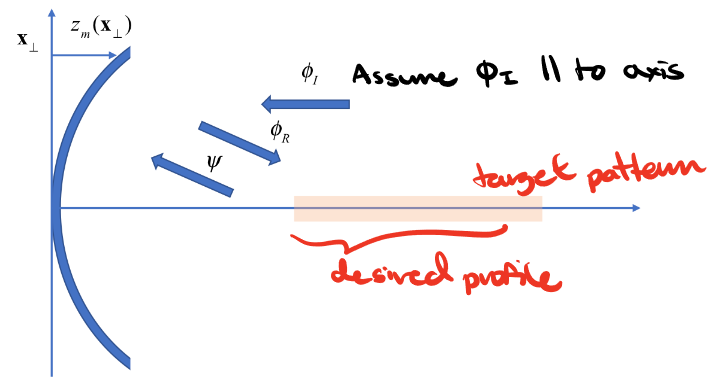

Surface of the mirror is defined by $z=z_m(x_{\perp})$. This is the function we want to optimize

Side note: Sagitta function of optic is defined as: $z(x_{\perp})=\frac{x_{\perp}^2}{R+\sqrt{R^2-(K+1)x_{\perp}^2}}$ where $R$ is the radius of curvature and $K$ is the conic constant

The incident wave $\phi_I$ (assume parallel to axis) comes from the right strikes the mirror and become a reflected wave, $\phi_R$. The reflected wave crosses the z-axis and creates a traveling pulse in the shaded region. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv,jn_zeros,expi
from scipy.optimize import curve_fit
from scipy.integrate import trapezoid,simpson,romb
from numpy.fft import *
import math
from gaussian_beam import *
import time
font = {'size'   : 26}

plt.rc('font', **font)
plt.rcParams['figure.figsize'] = (16,9)
plt.rcParams["lines.linewidth"] = 4


In [2]:
def create_starting_optic(r,R,k=-1):
    z=r*r/(R+np.sqrt(R*R-(k+1)*r*r))
    return z

This function defines the r and k array for a Hankel Transform:

* `N` is the total number of grid points
* `R` is the maximum radius
* `ell` is the order of the Bessel function


In [3]:
def DHTarrays(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    r=R*Zeroes[:N]/Zeroes[N-1]
    k=Zeroes[:N]/R
    return np.array([r,k])

This function defines the Transform Matrix for the Hankel Transform
* `N` is the total number of grid points
* `R` is the maximum radius
* `ell` is the order of the Bessel function
* `T_R2K` transforms from r space to k space
* `T_K2R` transforms from k space to r space


In [4]:
def DHTtransformMatrix(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    alpha=Zeroes[:N]
    kR = alpha[N-1]
    kmax = kR/R;
    T = jv(ell,np.outer(alpha,alpha)/kR) / np.outer( abs(jv(ell+1,alpha)),abs(jv(ell+1,alpha)) ) / kR;
    #print(T)
    A = abs(jv(ell+1,alpha));
    T_R2K = 4.0*np.pi*(R/kmax)*T * A[:, None] / A[None,:] 
    T_K2R = (1/np.pi)*(kmax/R)*T * A[:, None] / A[None,:] 

    return T_R2K,T_K2R

In [5]:
def mirror(phiI,k0,zm):
    return phiI*np.exp(-2j*k0*zm)

In [6]:
def propagate(fe, k, k0, z, T_R2K, T_K2R):
    # 1) fe is the initial electric field
    # 2) Hankel transform the field through multiplying by the appropriate transform matrix
    FT = T_R2K @ fe
    # Hankel Transform
    # 3) Propagate 𝐸̃ from 𝑧 = 0 to 𝑧 = Δ𝑧 through multiplying 𝐸̃ by the diffractive phase:
    FT = FT * np.exp(-1j * k**2 / (2 * k0) * z[:, np.newaxis])
    # print(FT.shape)
    # print(T_K2R.shape)
    # 4) Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = T_K2R @ (FT.T)
    # fT = (T_K2R@(FT.T)).T
    # print(np.shape(fT))
    return fT

In [7]:
def forward_propagation(k, phi_I, T_R2K, T_K2R, zF, zm, wavelength=1e-6):
    k0 = 2 * np.pi / wavelength
    #     fT_i=prop(phi_I,k,k0,zI,T_R2K,T_K2R)
    phi_R0 = mirror(phi_I, k0, zm)

    fT_f = propagate(phi_R0, k, k0, zF, T_R2K, T_K2R)

    return fT_f

In [9]:
def retrieve_bounds(z,zi,zf):
    i=len(z[z-zi<0])
    f=len(z[z-zf<=0])
    return i,f

In [10]:
def w_xp(r,R):
#     return np.exp(-r**2/R**2)
    delta=np.zeros(len(r))
    delta[0]=1
    return delta

In [11]:
def w_z(z,zi,zf):
    i,f=retrieve_bounds(z,zi,zf)
    w=np.zeros(len(z))
    w[i:f]=1
    return w

In [12]:
def integrate(r,z,phi1,phi2,method=simpson):
    return np.abs(2*np.pi*method(method(phi1*np.conj(phi2)*r[:,np.newaxis],z),r))

In [13]:
def weighted_phi(r,R,z,zi,zf,phi_r,phi_t):
    pr=phi_r*w_z(z,zi,zf)*w_xp(r,R)[:,np.newaxis]
    pt=phi_t*w_z(z,zi,zf)*w_xp(r,R)[:,np.newaxis]
    return pr,pt

In [14]:
def int_pairs(r,z,pr,pt):
    phi_r_sq=integrate(r,z,pr,pr)
    phi_r_phi_t=integrate(r,z,pr,pt)
    phi_t_sq=integrate(r,z,pt,pt)
    return phi_r_sq,phi_r_phi_t,phi_t_sq